In [1]:
# import the necessary package
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
# 1. Target Hotspots of Interest
hotspot_east = {
    "PIK3CA": ["p.H1047R", "p.E545K", "p.E542K", "p.N345K", "p.H1047L", "p.C420R"],
    "AKT1":   ["p.E17K"],
    "ERBB2":  ["p.V777L"],
    "PTEN":   ["p.L193P"],
    "TP53":   ["p.R248Q", "p.R248W", "pR249"],
    "BRCA2":  ["p.E7K"]
}

hotspot_west = {
    "PIK3CA": ["p.H1047R", "p.E545K", "p.E542K", "p.Q546K", "p.Q546R", "p.C420R"],
    "AKT1":   ["p.E17K"],
    "ESR1":  ["p.D538G", "p.Y537S", "p.Y537C", "p.Y537N", "p.E380Q"],
    "PTEN":   ["p.R130Q", "p.R130G"],
}

# Load the dataset
def load_and_standardize_file(file_dataset):
    """Reads all files and standardizes column headers."""
    base_dir = os.getcwd()
    files = sorted(glob.glob(file_dataset))
    dfs = []

    if not files:
        raise FileNotFoundError(
            f"No matching files found for pattern: {file_dataset!r} "
            f"from cwd={base_dir}"
        )
    
    for f in files:
        if not os.path.isfile(f):
            continue

        gene = os.path.basename(f).split("_")[0]
        df_sub = pd.read_csv(f, sep="\t", low_memory=False)
        
        # Standardize Sample ID column
        sample_col = [c for c in df_sub.columns if c in ["Tumor_Sample_Barcode", "Sample ID", "Sample_ID", "sampleId"]][0]
        # Standardize Protein Change column
        prot_col = [c for c in df_sub.columns if c in ["HGVSp_Short", "Protein Change", "Protein_Change", "proteinChange"]][0]
        
        df_sub = df_sub[[sample_col, prot_col]].dropna()
        df_sub.columns = ["Sample_ID", "Protein_Change"]
        df_sub["Gene"] = gene
        
        # Ensure 'p.' prefix format
        df_sub["Protein_Change"] = df_sub["Protein_Change"].apply(
            lambda x: f"p.{x}" if not str(x).startswith("p.") else str(x)
        )
        dfs.append(df_sub)
        
    combined = pd.concat(dfs, ignore_index=True)
    return combined

# Compute greedy coverage
def compute_greedy_coverage_east(df, cohort_size, max_k=13):
    """Executes Greedy Maximum Coverage across matched targets."""
    # Build list of target identifiers
    target_pool = []
    for g, vlist in hotspot_east.items():
        for v in vlist:
            target_pool.append((g, v))
            
    # Map target -> set of samples harboring it
    target_to_samples = {}
    for g, v in target_pool:
        matched = set(df[(df["Gene"] == g) & (df["Protein_Change"] == v)]["Sample_ID"])
        if len(matched) > 0:
            target_to_samples[f"{g} {v}"] = matched
            
    total_cohort_samples = cohort_size
    uncovered = set(df["Sample_ID"].unique())
    covered = set()
    ranked_results = []
    
    for rank in range(1, min(max_k, len(target_to_samples)) + 1):
        best_target = None
        best_gain = -1
        
        for target, samples in target_to_samples.items():
            if target in [r["Target"] for r in ranked_results]:
                continue
            gain = len(samples.intersection(uncovered))
            if gain > best_gain:
                best_gain = gain
                best_target = target
                
        if best_target is None or best_gain == 0:
            break
            
        new_samples = target_to_samples[best_target]
        covered.update(new_samples)
        uncovered.difference_update(new_samples)
        
        cum_cov_pct = (len(covered) / total_cohort_samples) * 100
        indiv_pct = (len(new_samples) / total_cohort_samples) * 100
        gain_pct = (best_gain / total_cohort_samples) * 100
        
        ranked_results.append({
            "Rank": rank,
            "Target": best_target,
            "Individual_%": round(indiv_pct, 2),
            "Marginal_Gain_%": round(gain_pct, 2),
            "Cumulative_N": len(covered),
            "Cumulative_%": round(cum_cov_pct, 2)
        })
        
    res_df = pd.DataFrame(ranked_results)
    return res_df, total_cohort_samples

def compute_greedy_coverage_west(df, cohort_size, max_k=15):
    """Executes Greedy Maximum Coverage across matched targets."""
    # Build list of target identifiers
    target_pool = []
    for g, vlist in hotspot_west.items():
        for v in vlist:
            target_pool.append((g, v))
            
    # Map target -> set of samples harboring it
    target_to_samples = {}
    for g, v in target_pool:
        matched = set(df[(df["Gene"] == g) & (df["Protein_Change"] == v)]["Sample_ID"])
        if len(matched) > 0:
            target_to_samples[f"{g} {v}"] = matched
            
    total_cohort_samples = cohort_size
    uncovered = set(df["Sample_ID"].unique())
    covered = set()
    ranked_results = []
    
    for rank in range(1, min(max_k, len(target_to_samples)) + 1):
        best_target = None
        best_gain = -1
        
        for target, samples in target_to_samples.items():
            if target in [r["Target"] for r in ranked_results]:
                continue
            gain = len(samples.intersection(uncovered))
            if gain > best_gain:
                best_gain = gain
                best_target = target
                
        if best_target is None or best_gain == 0:
            break
            
        new_samples = target_to_samples[best_target]
        covered.update(new_samples)
        uncovered.difference_update(new_samples)
        
        cum_cov_pct = (len(covered) / total_cohort_samples) * 100
        indiv_pct = (len(new_samples) / total_cohort_samples) * 100
        gain_pct = (best_gain / total_cohort_samples) * 100
        
        ranked_results.append({
            "Rank": rank,
            "Target": best_target,
            "Individual_%": round(indiv_pct, 2),
            "Marginal_Gain_%": round(gain_pct, 2),
            "Cumulative_N": len(covered),
            "Cumulative_%": round(cum_cov_pct, 2)
        })
        
    res_df = pd.DataFrame(ranked_results)
    return res_df, total_cohort_samples

# Plot coverage curve
def plot_coverage_curve(res_df, cohort_n, plot_title):
    """Generates the cumulative coverage plot."""
    plt.figure(figsize=(10, 5.5))
    plt.plot(res_df["Rank"], res_df["Cumulative_%"], marker="o", color="#005b96", linewidth=2.5, markersize=7)
    
    for _, r in res_df.iterrows():
        plt.annotate(
            f"{r['Target'].split(' ')[1]}\n({r['Cumulative_%']}%)",
            (r["Rank"], r["Cumulative_%"]),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=8
        )
        
    plt.title(f"Cumulative Patient Coverage vs. Number of Targets\n({plot_title}, N={cohort_n})", fontsize=12, fontweight="bold")
    plt.xlabel("Number of Targets in Panel (Rank 1 to K)", fontsize=10, fontweight="semibold")
    plt.ylabel("% Patients with ≥ 1 Actionable Variant", fontsize=10, fontweight="semibold")
    plt.ylim(0, max(res_df["Cumulative_%"].max() + 12, 100))
    plt.xticks(res_df["Rank"])
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()



 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1 PIK3CA p.H1047R         10.14            10.14             7         10.14
    2     AKT1 p.E17K          4.35             4.35            10         14.49
    3  PIK3CA p.E542K          1.45             1.45            11         15.94
    4  PIK3CA p.N345K          1.45             1.45            12         17.39
    5  PIK3CA p.C420R          1.45             1.45            13         18.84
    6    TP53 p.R248Q          1.45             1.45            14         20.29
    7    TP53 p.R248W          1.45             1.45            15         21.74


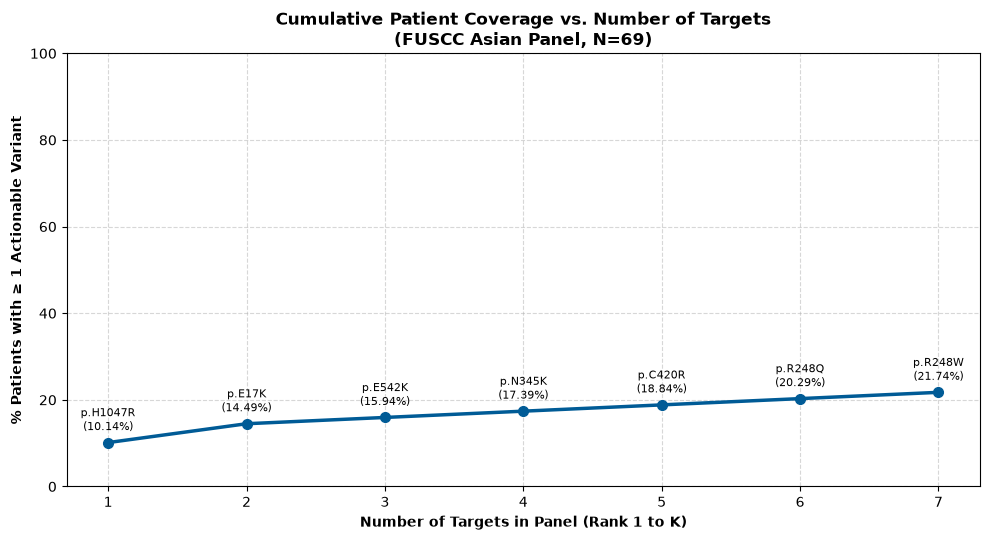

In [27]:
# Execute FUSCC for Asian Panel
fuscc_east_df = load_and_standardize_file("/home/marvel/Bioinfo_All/hackaton/coverage_curve/FUSCC_asianpanel/*_FUSCC.tsv")
summary_table, cohort_size = compute_greedy_coverage_east(fuscc_east_df, 69, max_k=13)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='FUSCC Asian Panel')

 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1 PIK3CA p.H1047R         10.14            10.14             7         10.14
    2     AKT1 p.E17K          4.35             4.35            10         14.49
    3  PIK3CA p.E542K          1.45             1.45            11         15.94
    4  PIK3CA p.C420R          1.45             1.45            12         17.39


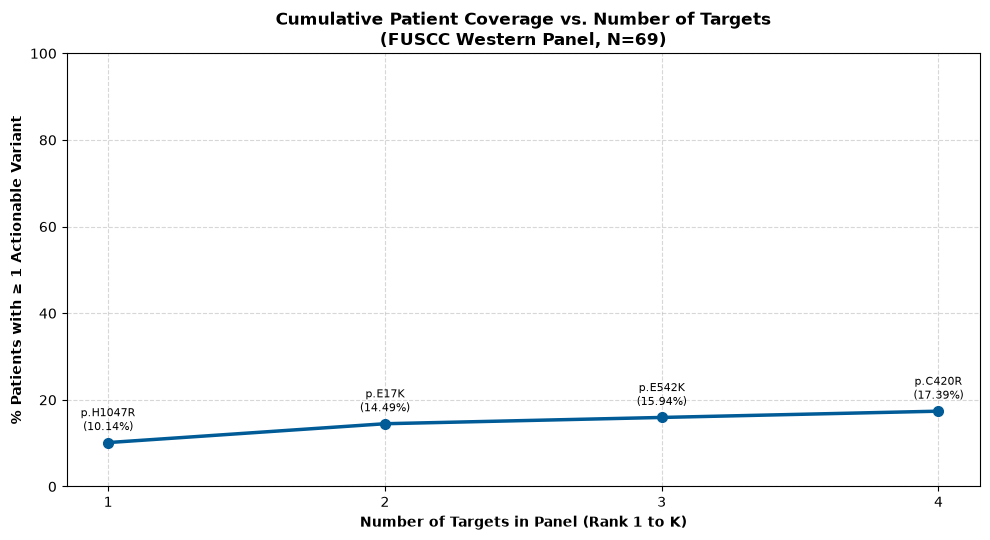

In [28]:
# Execute FUSCC for Western Panel
fuscc_west_df = load_and_standardize_file("/home/marvel/Bioinfo_All/hackaton/coverage_curve/FUSCC_westpanel/*_FUSCC.tsv")
summary_table, cohort_size = compute_greedy_coverage_west(fuscc_west_df, 69, max_k=15)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='FUSCC Western Panel')

 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1 PIK3CA p.H1047R         13.61            13.61           261         13.61
    2  PIK3CA p.E545K          8.29             8.24           419         21.85
    3  PIK3CA p.E542K          5.16             5.11           517         26.96
    4     AKT1 p.E17K          4.80             4.59           605         31.54
    5  PIK3CA p.N345K          2.66             2.66           656         34.20
    6 PIK3CA p.H1047L          1.82             1.82           691         36.03
    7  PIK3CA p.C420R          1.09             1.09           712         37.12
    8    TP53 p.R248Q          0.94             0.57           723         37.70
    9    TP53 p.R248W          0.63             0.42           731         38.11
   10   ERBB2 p.V777L          0.36             0.26           736         38.37


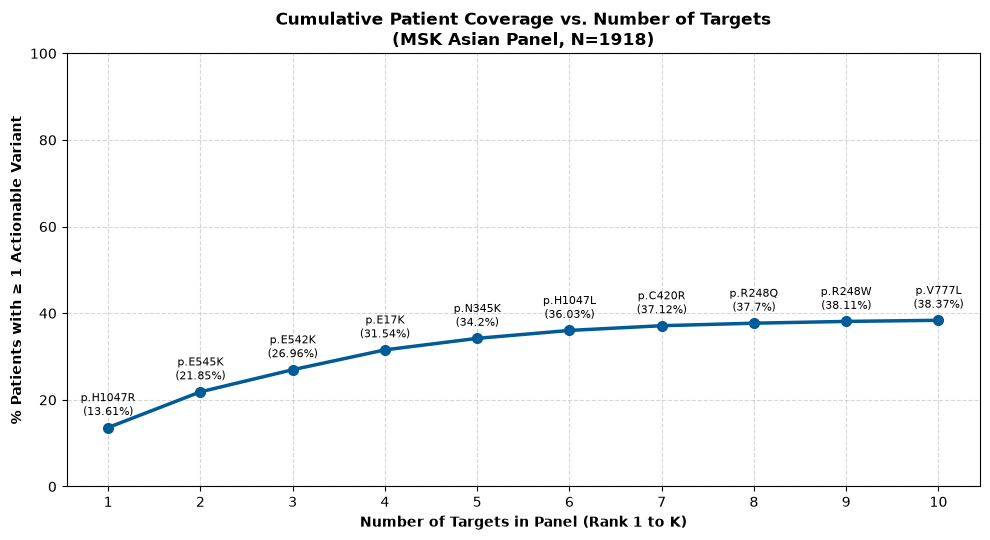

In [ ]:
# Execute MSK for Asian Panel
MSK_east_df = load_and_standardize_file("/home/marvel/Bioinfo_All/hackaton/coverage_curve/MSK_asianpanel/*_MSK.tsv")
summary_table, cohort_size = compute_greedy_coverage_east(MSK_east_df, 1918, max_k=13)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='MSK Asian Panel')

 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1 PIK3CA p.H1047R         13.61            13.61           261         13.61
    2  PIK3CA p.E545K          8.29             8.24           419         21.85
    3  PIK3CA p.E542K          5.16             5.11           517         26.96
    4     AKT1 p.E17K          4.80             4.59           605         31.54
    5    ESR1 p.D538G          2.97             2.14           646         33.68
    6    ESR1 p.Y537S          1.93             1.15           668         34.83
    7  PIK3CA p.C420R          1.09             1.04           688         35.87
    8    ESR1 p.E380Q          0.89             0.52           698         36.39
    9    ESR1 p.Y537C          0.68             0.36           705         36.76
   10    ESR1 p.Y537N          0.52             0.36           712         37.12
   11  PIK3CA p.Q546R          0.36             0.26           717         37.38
   12  PIK3CA p.Q546K       

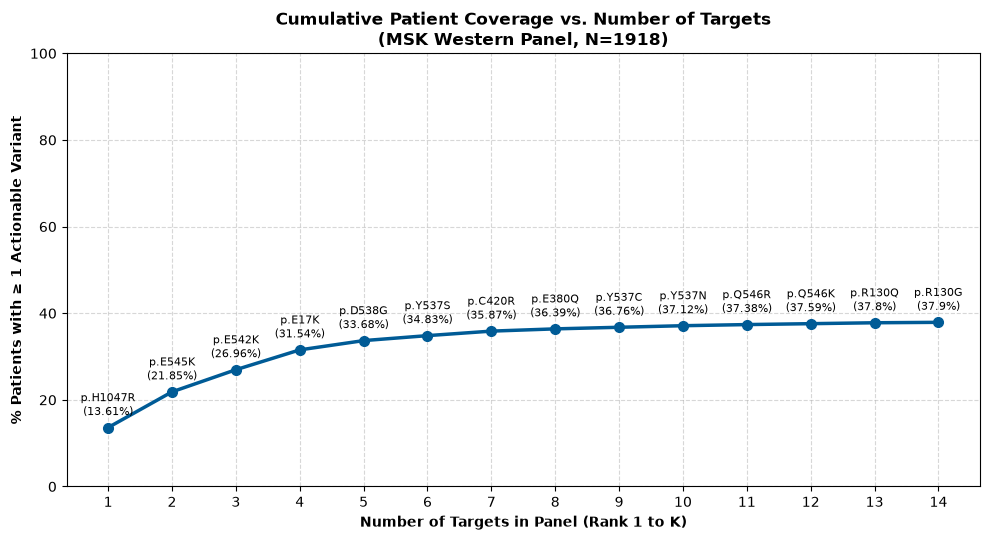

In [ ]:
# Execute MSK for Western Panel
MSK_west_df = load_and_standardize_file("/home/marvel/Bioinfo_All/hackaton/coverage_curve/MSK_westpanel/*_MSK.tsv")
summary_table, cohort_size = compute_greedy_coverage_west(MSK_west_df, 1918, max_k=15)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='MSK Western Panel')

In [34]:
# define special sample: INDO.tsv
import pandas as pd

# Load the aggregated summary TSV
df_summary = pd.read_csv("./coverage_curve/Indo/INDO.tsv", sep="\t")

# Clean column names
df_summary.columns = [c.strip() for c in df_summary.columns]

# Expand aggregated counts into individual sample rows
sample_rows = []
sample_idx = 1

for _, row in df_summary.iterrows():
    mut = str(row["Specific PIK3CA Mutation Location"]).strip()
    if not mut or mut == "nan":
        continue
    count = int(row["Count"])
    for _ in range(count):
        sample_rows.append({
            "Sample_ID": f"INDO_PT_{sample_idx:03d}",
            "Protein_Change": f"p.{mut}" if not mut.startswith("p.") else mut,
            "Gene": "PIK3CA"
        })
        sample_idx += 1

df_expanded = pd.DataFrame(sample_rows)
# Save with standard prefix expected by your glob pattern: gene = basename.split('_')[0]
df_expanded.to_csv("PIK3CA_INDO.tsv", sep="\t", index=False)

 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1 PIK3CA p.H1047L         35.29            35.29            24         35.29
    2  PIK3CA p.E542K         13.24            13.24            33         48.53
    3 PIK3CA p.H1047R         11.76            11.76            41         60.29
    4  PIK3CA p.E545K          7.35             7.35            46         67.65


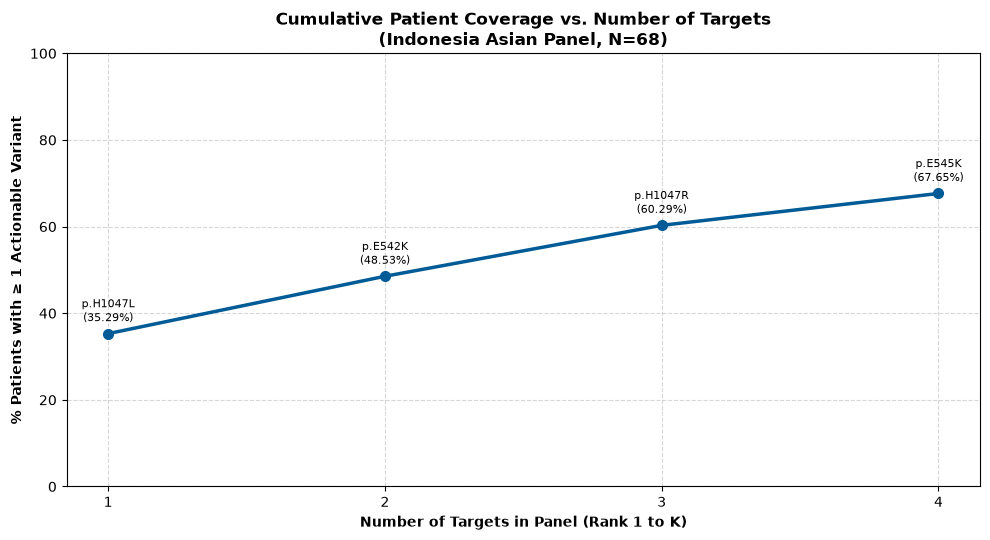

In [36]:
# Execute INDO for Asian Panel
INDO_east_df = load_and_standardize_file("./PIK3CA_INDO.tsv")
summary_table, cohort_size = compute_greedy_coverage_east(INDO_east_df, 68, max_k=13)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='Indonesia Asian Panel')

 Rank          Target  Individual_%  Marginal_Gain_%  Cumulative_N  Cumulative_%
    1  PIK3CA p.E542K         13.24            13.24             9         13.24
    2 PIK3CA p.H1047R         11.76            11.76            17         25.00
    3  PIK3CA p.E545K          7.35             7.35            22         32.35
    4  PIK3CA p.Q546R          5.88             5.88            26         38.24


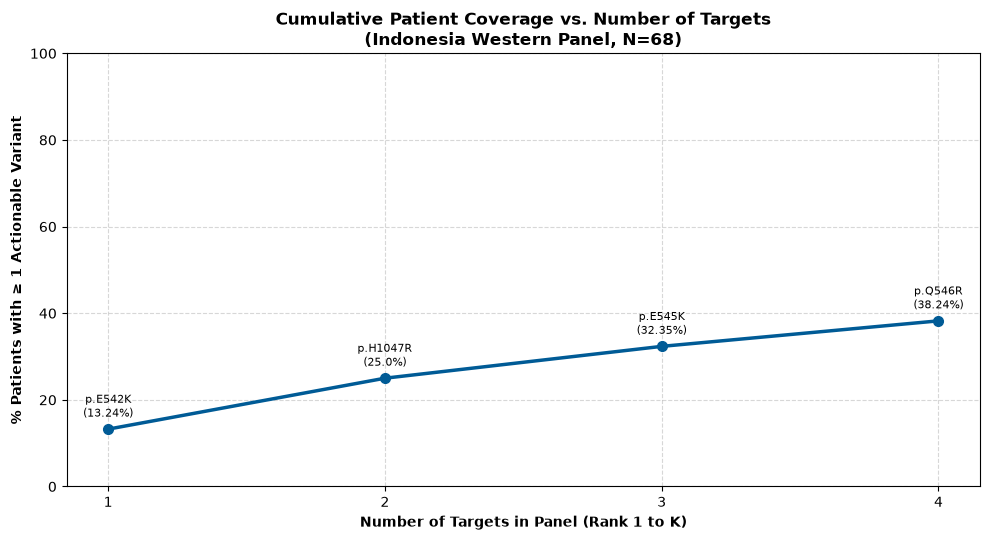

In [37]:
# Execute INDO for Western Panel
INDO_west_df = load_and_standardize_file("./PIK3CA_INDO.tsv")
summary_table, cohort_size = compute_greedy_coverage_west(INDO_west_df, 68, max_k=15)
print(summary_table.to_string(index=False))
plot_coverage_curve(summary_table, cohort_size, plot_title='Indonesia Western Panel')